# Simulator tour
A hands-on tour of the Simulator stage (`galactic_tidal_constraints.simr.sim`): it runs one SPAM galaxy
collision and returns arrays. Run the cells top to bottom.

**To run it** (from this repo's root, in bash or PowerShell), then open the `127.0.0.1` link it prints:
```bash
docker run --rm -it -p 8888:8888 -v "${PWD}:/gtc" -w /gtc -e UV_PROJECT_ENVIRONMENT=/tmp/venv \
    ogdenm12/gtc-base-image:v2 uv run --group notebook jupyter lab --ip=0.0.0.0 --allow-root --no-browser
```
- `-v "${PWD}:/gtc"` mounts this repo into the container, so edits on Windows show up immediately.
- `UV_PROJECT_ENVIRONMENT=/tmp/venv` keeps the Linux virtual environment inside the container, out of the repo.
  It's rebuilt each time the container starts (a minute or two, mostly compiling SPAM).
- Our package is installed in editable mode. After editing a `.py` file, restart the kernel to pick it up.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from galactic_tidal_constraints.simr import sim

## The 22 collision parameters
A SPAM model is 22 numbers, usually written as a comma-separated model string. In code, a model is a plain
array of shape `(22,)`, and `sim.PARAM_NAMES` names each position, using the names in SPAM's Fortran:

| Names | Meaning |
|---|---|
| `x, y, z, vx, vy, vz` | The secondary's position and velocity relative to the primary |
| `mass1, mass2` | The two masses |
| `rout1, rout2` | The two disk radii |
| `phi1, phi2, theta1, theta2` | The two disks' orientations, in degrees |
| `epsilon1, epsilon2` | Softening for gravity between the two centers |
| `rscale1_1` … `rscale2_3` | Three scale values per galaxy (usually all 0) |

Galaxy 1 is the primary, and stays at the origin. Galaxy 2 is the secondary. This model is SDSS
587722984435351614, from JSPAM's `archive/data.txt`. Its line has 34 values; like SPAM,
`parse_model_string` reads the first 22.

In [2]:
MODEL_STRING = "-9.93853,-4.5805,15.43348,-1.54025,-2.97899,4.69234,34.41671,29.49607,2.97913,4.2501,301.0,35.5,310.80745,321.98757,0.3,0.3,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0,0,0.24008,-2.41999,5.62715,0.0,1.0,0.0,1.0,0.0,0.0"

params = sim.parse_model_string(MODEL_STRING)
dict(zip(sim.PARAM_NAMES, params.tolist()))

{'x': -9.93853,
 'y': -4.5805,
 'z': 15.43348,
 'vx': -1.54025,
 'vy': -2.97899,
 'vz': 4.69234,
 'mass1': 34.41671,
 'mass2': 29.49607,
 'rout1': 2.97913,
 'rout2': 4.2501,
 'phi1': 301.0,
 'phi2': 35.5,
 'theta1': 310.80745,
 'theta2': 321.98757,
 'epsilon1': 0.3,
 'epsilon2': 0.3,
 'rscale1_1': 0.0,
 'rscale1_2': 0.0,
 'rscale1_3': 0.0,
 'rscale2_1': 0.0,
 'rscale2_2': 0.0,
 'rscale2_3': 0.0}

To read or change one value by name, look up its position in `sim.PARAM_INDEX`. Copy the array first, so the
original model stays as it was.

In [3]:
heavier = params.copy()
heavier[sim.PARAM_INDEX["mass2"]] *= 2
print("mass2:", params[sim.PARAM_INDEX["mass2"]], "->", heavier[sim.PARAM_INDEX["mass2"]])

mass2: 29.49607 -> 58.99214


## One SPAM run
`sim.simulate(params, n1, n2)` runs the collision with `n1` and `n2` particles in the two disks, and returns
x, y, z, vx, vy, vz of every particle at the end, shape `(n1 + n2 + 1, 6)`. The last row is the secondary's
center.

In [4]:
N1, N2 = 2000, 2000

particles = sim.simulate(params, n1=N1, n2=N2)
print("shape:", particles.shape)
print("secondary's center (x, y, z, vx, vy, vz):", particles[-1])

shape: (4001, 6)
secondary's center (x, y, z, vx, vy, vz): [-9.94007008 -4.58347891 15.43817208 -1.5399158  -2.97883593  4.69182098]


The secondary's center nearly matches `x, y, z, vx, vy, vz` above. The 22 values describe the system *now*,
as observed. SPAM first runs the two centers backward to find a start time before the encounter, places the
disks there, then runs everything forward and stops at about "now" (a step or two past it). So a run ends at
the observed moment, with the tidal features formed.

Split the rows into the two disks and plot x against y:

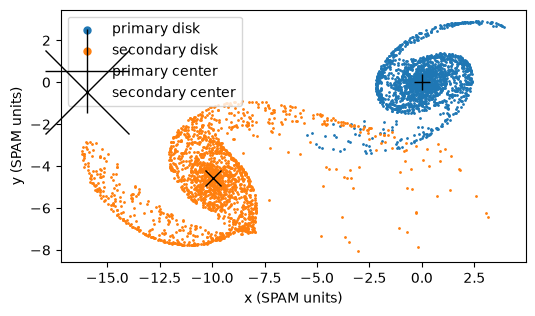

In [5]:
primary = particles[:N1]
secondary = particles[N1:N1 + N2]
center2 = particles[-1]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(primary[:, 0], primary[:, 1], s=1, label="primary disk")
ax.scatter(secondary[:, 0], secondary[:, 1], s=1, label="secondary disk")
ax.plot(0, 0, "k+", ms=12, label="primary center")
ax.plot(center2[0], center2[1], "kx", ms=12, label="secondary center")
ax.set_aspect("equal")
ax.set_xlabel("x (SPAM units)")
ax.set_ylabel("y (SPAM units)")
ax.legend(markerscale=5)
plt.show()

Run it again and compare. The disk particles start from unseeded random positions, so they differ every
run. The secondary's center doesn't depend on them, so it matches.

In [6]:
again = sim.simulate(params, n1=N1, n2=N2)
print("secondary's center matches:", np.allclose(again[-1], particles[-1]))
print("disk particles match:      ", np.allclose(again[:-1], particles[:-1]))

secondary's center matches: True
disk particles match:       False
